In [1]:
import subprocess
import sys

COLAB = "google.colab" in sys.modules


def _install(package):
    if COLAB:
        ans = input(f"Install { package }? [y/n]:")
        if ans.lower() in ["y", "yes"]:
            subprocess.check_call(
                [sys.executable, "-m", "pip", "install", "--quiet", package]
            )
            print(f"{ package } installed!")


def _colab_install_missing_deps(deps):
    import importlib

    for dep in deps:
        if importlib.util.find_spec(dep) is None:
            if dep == "iris":
                dep = "scitools-iris"
            _install(dep)


deps = ["ioos_qc"]
_colab_install_missing_deps(deps)

In [2]:
import ioos_qc
print(ioos_qc.__version__)

0.1.dev812+g6f4439a2c


#   IOOS QARTOD on Glider Data
Created: 2026-10-02

Updated: 2026-10-22

During the 2026 Google Summer of Code, a project was [proposed to evaluate](https://github.com/ioos/gsoc/issues/102) the tests present in the [QARTOD glider manual](https://cdn.ioos.noaa.gov/media/2017/12/Manual-for-QC-of-Glider-Data_05_09_16.pdf), which had recently turned 10 years old. The final project was called ["Filling the gaps within the IOOS quality control schema for ocean glider data"](https://summerofcode.withgoogle.com/programs/2026/projects/bJGGUbsA) which led to a [series of investigative notebooks](https://github.com/Klankers/mau_gsoc_qartod) that did the following for tests listed within the manual:
1. Looked at the manual's description and assessed if it made sense.
2. Looked within the [IOOS QC codebase](https://github.com/ioos/ioos_qc/tree/main/ioos_qc) and assessed if it was authentic and genuine to the manual. If not, look at where the differences were and what they would do in practice.
3. Given the unknown recent activity of the manual's original authors, make additions or changes to the QARTOD toolbox to more comprehensively perform what is described in the manual.

This general procedure was done for the following tests:
1. Timing/Gap Test
2. Syntax Test
3. Location Test
4. Gross Range Test
5. Pressure Test
6. Climatology Test
14. (As ordered in the manual) Density Inversion Test

This notebook seeks to demonstrate how the tests can be used on ocean glider datasets. Unfortunately, the following tests were not assessed:

7. Spike Test
8. Rate of Change Test
9. Flat Line TEst
10. Multi-Variate Test
11. Attenuated Signal Test
12. Previous Profile Test
13. TS Curve/Space Test

As such, these tests will not be listed in this notebook unless updated at a later date.

Experimentation during the 2026 Google Summer of Code was commonly done on gliders using the [OG1 format](https://oceangliderscommunity.github.io/OG-format-user-manual/OG_Format.html). Plots, statistics, and any other outputs from this notebook are therefore entirely intended for educational purposes and are not intended to critically reflect on the dataset being used. Note that the results and settings present in this notebook may differ from those found at other institutions.

Data for this notebook is sourced from the Voice of the Ocean Foundation's ALSEAMAR *SeaExplorer* fleet, operating in the [Skagerrak](https://en.wikipedia.org/wiki/Skagerrak) between 2021 and 2026. This region is characterized by the interaction between deep, salty water from the [North Sea](https://en.wikipedia.org/wiki/North_Sea) interacting with fresh, relatively warm outflow from the [Baltic Sea](https://en.wikipedia.org/wiki/Baltic_Sea), passing through the [Danish Straits](https://en.wikipedia.org/wiki/Danish_Straits) and [Kattegat](https://en.wikipedia.org/wiki/Kattegat). This gives a temperature profile that is normally expected (warmest water at the surface), though the salinity profile is opposite of that typical in ocean gyres or open ocean (here, fresh water is on top).

The dataset to be used is [mission #109 of SeaExplorer number 044](https://erddap.observations.voiceoftheocean.org/erddap/files/OG_complete_SEA044_M109/), operating for 20 days in September 2025.

This notebook is continued from part 1, which covers the flags, the Timing/Gap Test and the Syntax Test. This part covers the Location Tests. The setup from part 1 is repeated below, followed by the overview figure as a quick refresher.

## Load the data
Starting with imports and loading the dataset.

In [3]:
#   For loading data
import pooch
import xarray as xr

#   Contains all of our tests
from ioos_qc import qartod

#   20261022: Extracting all the plotting code.
#   The plotting helpers live next to this notebook. The file name isn't a valid module name, so load it by path.
import importlib.util
spec = importlib.util.spec_from_file_location("plotting_helpers", "2026-10-22-QARTOD-help-plot.py")
plotting_helpers = importlib.util.module_from_spec(spec)
spec.loader.exec_module(plotting_helpers)

url = "https://erddap.observations.voiceoftheocean.org/erddap/files/OG_complete_SEA044_M109/"
fname = "sea044_20250905T0639_delayed.nc"
filehash = "0bce25b78fc40bd7888a76909faa60b4f6490afd44b68a7f1f56c9d7611020ab"
#   VOTO's file hashes are not public as of September 2026. I've computed it using Python's 'hashlib'

download = pooch.retrieve(
    url=f"{url}{fname}",
    known_hash=f"sha256:{filehash}"
)
ds = xr.open_dataset(download)
ds

<xarray.Dataset> Size: 245MB
Dimensions:                             (N_MEASUREMENTS: 1699082)
Coordinates:
  * N_MEASUREMENTS                      (N_MEASUREMENTS) int64 14MB 0 ... 169...
    LATITUDE                            (N_MEASUREMENTS) float64 14MB ...
    LONGITUDE                           (N_MEASUREMENTS) float64 14MB ...
    TIME                                (N_MEASUREMENTS) datetime64[ns] 14MB ...
    DEPTH                               (N_MEASUREMENTS) float64 14MB ...
Data variables: (12/31)
    AD2CP_HEADING                       (N_MEASUREMENTS) float32 7MB ...
    AD2CP_PITCH                         (N_MEASUREMENTS) float32 7MB ...
    AD2CP_ROLL                          (N_MEASUREMENTS) float32 7MB ...
    BBP700                              (N_MEASUREMENTS) float32 7MB ...
    CHLA                                (N_MEASUREMENTS) float32 7MB ...
    DIVE_NUMBER                         (N_MEASUREMENTS) int64 14MB ...
    ...                                  ...
    SENSOR_CURRENT_PROFILERS_105527     float64 8B ...
    SENSOR_DISSOLVED_GAS_SENSORS_0095   float64 8B ...
    SENSOR_FLUOROMETERS_235280          float64 8B ...
    SENSOR_MICROSTRUCTURE_SENSORS_0496  float64 8B ...
    PROFILE_NUMBER                      (N_MEASUREMENTS) int64 14MB ...
    PROFILE_DIRECTION                   (N_MEASUREMENTS) int64 14MB ...
Attributes: (12/67)
    Conventions:                                CF-1.10, OG-1.0, Unidata Data...
    acknowledgement:                            This study used data collecte...
    agency:                                     Voice of the Ocean
    agency_role:                                contact point
    agency_role_vocabulary:                     http://vocab.nerc.ac.uk/colle...
    cdm_data_type:                              Trajectory
    ...                                         ...
    start_date:                                 20250905T0639
    basin:                                      Skagerrak
    total_dives:                                616
    dataset_id:                                 delayed_SEA044_M109
    data_url:                                   https://erddap.observations.v...
    variables:                                  ['AD2CP_HEADING', 'AD2CP_PITC...

In [4]:
from ioos_qc.qartod import QartodFlags  #   These are stored in a Class in qartod
print(dir(QartodFlags))
print(f"Unknown flag = {QartodFlags.UNKNOWN}")

#   Each flag is tied to a label and a color in the plotting helpers.
flag_style = plotting_helpers.flag_style

['FAIL', 'GOOD', 'MISSING', 'SUSPECT', 'UNKNOWN', '__class__', '__delattr__', '__dict__', '__dir__', '__doc__', '__eq__', '__firstlineno__', '__format__', '__ge__', '__getattribute__', '__getstate__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__le__', '__lt__', '__module__', '__ne__', '__new__', '__reduce__', '__reduce_ex__', '__repr__', '__setattr__', '__sizeof__', '__static_attributes__', '__str__', '__subclasshook__', '__weakref__']
Unknown flag = 2


In [5]:
order = plotting_helpers.order
print(order)

[2, 1, 9, 3, 4]


In [6]:
import gsw
import numpy as np
ds["PSAL"] = gsw.SP_from_C(ds.CNDC, ds.TEMP, ds.PRES)
ds["SA"] = gsw.SA_from_SP(ds.PSAL, ds.PRES, ds.LONGITUDE, ds.LATITUDE)
ds["CT"] = gsw.CT_from_t(ds.SA, ds.TEMP, ds.PRES)
ds["SIGMA0"] = gsw.sigma0(ds.SA, ds.CT)

time = ds.TIME.values
pres = ds.PRES.values
temp = ds.TEMP.values
psal = ds.PSAL.values
sigma0 = ds.SIGMA0.values
profile = ds.PROFILE_NUMBER.values
direction = ds.PROFILE_DIRECTION.values  # 1 = descending, -1 = ascending

print(f"{time.size} measurements in {np.unique(profile).size} profiles")
print(f"{np.datetime_as_string(time[0], unit='m')} to {np.datetime_as_string(time[-1], unit='m')}")

1699082 measurements in 1232 profiles
2025-09-05T06:39 to 2025-09-25T09:24


In [7]:
#   This is a quick helper function that we can pass any flags into and get flag information out of
def flag_counts(flags, name=""):
    flags = np.ma.getdata(flags)
    parts = [
        f"{flag_style[f][0]}={np.count_nonzero(flags == f):,}" for f in order if np.any(flags == f)
    ]
    print(f"{name:<28s}" + ", ".join(parts))

In [8]:
extent = (8.8, 11.6, 57.4, 59.2)  # lon_min, lon_max, lat_min, lat_max

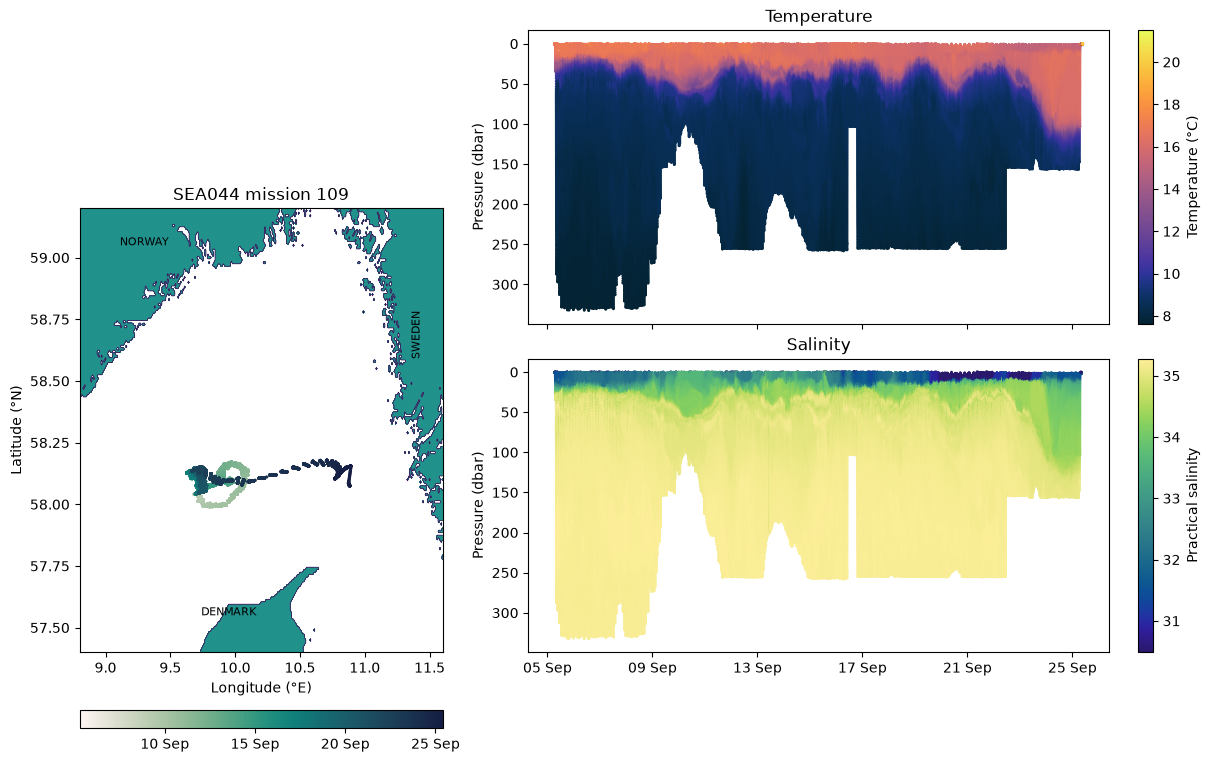

In [9]:
fig, axs = plotting_helpers.overview_figure(ds.LONGITUDE.values, ds.LATITUDE.values, time, pres, temp, psal, extent)

## Location Test
The location test, following the 2026 GSoC, has been expanded into additional tests based on the description of intended functionalities described in the manual.
* Location test - reworked to handle basic lat/lon bounds (|lat| ≤ 90, |lon| ≤ 180) and (optionally) defined distances between points.
* Location *on land* test - flagging points that are detected to be on land, using the GSHHG coastline database for quick, high-resolution results.
* Location *bounds* test - expanding on the original `location` test by taking a user-defined coordinate shape (not just a rectangle) and then flagging either inside or outside of a range. Handy when chaining areas together, such as MPAs inside of a survey area.

### New Location Test
Similar to the `syntax` test, let's illustrate some problems that we can test by intentionally breaking the lat/lon at specific indices.
* Let's SWAP the lat/lon - this should give a huge jump both at and after the index
* There's a latitude which is 100 deg *more* than it should be
* One of the lat/lon values are missing about halfway thorough the data - this should flag the point's index as bad.
* Both values are missing at the end - this should flag 9

In [10]:
import warnings
lat_bad, lon_bad = ds.LATITUDE.copy(), ds.LONGITUDE.copy()
# i_swap, i_typo, i_half, i_none = 20000, 45000, 70000, 90000
n = ds.LATITUDE.size
i_swap, i_typo, i_half, i_none = (int(f * n) for f in (0.2, 0.45, 0.5, 0.9))
print(f"{i_swap}, {i_typo}, {i_half}, {i_none}")

lat_bad[i_swap], lon_bad[i_swap] = ds.LONGITUDE[i_swap], ds.LATITUDE[i_swap]
lat_bad[i_typo] = ds.LATITUDE[i_typo] + 100
lon_bad[i_half] = np.nan
lat_bad[i_none] = lon_bad[i_none] = np.nan

range_max = 10000   #   Meters, so 10000 = 10 km
with warnings.catch_warnings():
    #   158N isn't a valid latitude, which triggers a harmless RuntimeWarning
    warnings.simplefilter("ignore", RuntimeWarning)
    flags_loc = qartod.location_test(lon_bad, lat_bad, range_max=range_max, range_method="wgs84")

flag_counts(flags_loc, f"range_max = {range_max / 1000:.0f} km:")
for i, what in [(i_swap, "swapped"), (i_typo, "typo"), (i_half, "one missing"), (i_none, "both missing")]:
    print(f"  {what:<13s} flags (point before, point, point after): {np.ma.getdata(flags_loc)[i - 1:i + 2]}")

339816, 764586, 849541, 1529173
range_max = 10 km:          GOOD=1,699,077, MISSING=1, SUSPECT=2, FAIL=2
  swapped       flags (point before, point, point after): [1 3 3]
  typo          flags (point before, point, point after): [1 4 1]
  one missing   flags (point before, point, point after): [1 4 1]
  both missing  flags (point before, point, point after): [1 9 1]


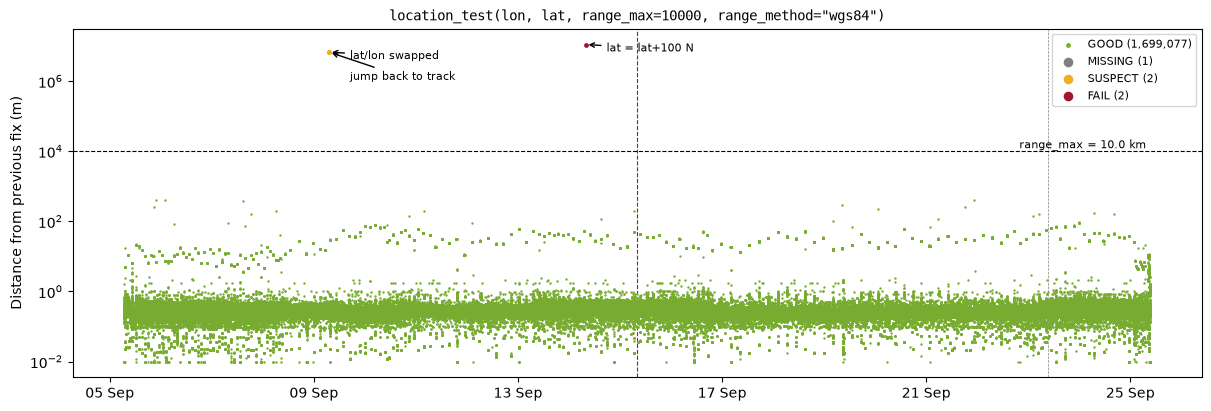

In [11]:
fig, ax = plotting_helpers.location_distance_figure(
    ds.TIME, lon_bad, lat_bad, flags_loc, range_max, i_swap, i_typo, i_half, i_none,
)

The cell above shows the distance between the points - most are within a meter apart from each other. There are actually two points at the beginning of the 9th of September because of the lat/lon swap - the calculation catches the jump back as well which is approximately the same magnitude as the initial one. The distance can't be calculated when a point is missing - so those are the vertical red and grey lines at the indices where the problem arises.

### Location on Land Test
Since our data is good, demonstrating these new tests is easiest to demonstrate by "damaging" the data again. Let's shift a few days of data north onto land.

In [12]:
import shapely
lat_shift = ds.LATITUDE.copy()
shifted = (ds.TIME > np.datetime64("2025-09-17")) & (ds.TIME < np.datetime64("2025-09-20"))
lat_shift[shifted] += 0.9

flags_land = qartod.location_on_land_test(ds.LONGITUDE, lat_shift)

If we zoom way into the Norwegian coast, we can see the high resolution afforded to us with `roaring_landmask` - especially valuable for glider operators that operate near the coast. For a comparison against `regionmask`, which uses Natural Earth, see the GSoC'26 [deliverable 2 notebook](https://github.com/Klankers/mau_gsoc_qartod/blob/main/deliverable_2.ipynb).

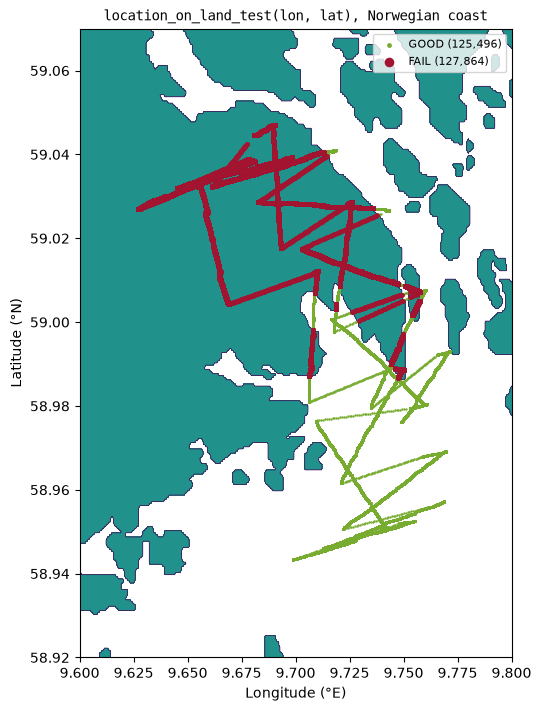

In [13]:
zoom_extent = (9.6, 9.8, 58.92, 59.07)
fig, ax = plotting_helpers.land_zoom_figure(
    ds.LONGITUDE[shifted], lat_shift[shifted], flags_land[shifted], zoom_extent,
    title="location_on_land_test(lon, lat), Norwegian coast",
)

### Location bounds
And now to show what this data looks like with the `location bounds test` in place. Say we want to define a working area that we're not expecting the glider to leave (`operating_area`), as well as another area that the glider should *not* be working in, like a shipping lane or MPA (`exclusion_zone`).

On our newly shifted data, we should see that there are flags that are inside and outside of the two bounded areas we've designated. QARTOD has a flag aggregator, `qartod_compare`, which can be used to summarize all these flags in the end (`flags_bounds`).

In [14]:
#   Setting up for a survey area, with an exclusion zone inside to demonstrate chaining
operating_area = shapely.Polygon([(9.45, 57.92), (11.0, 57.92), (11.0, 58.28), (9.45, 58.28)])
exclusion_zone = shapely.Polygon([(10.15, 58.0), (10.35, 58.0), (10.35, 58.2), (10.15, 58.2)])
flags_outside = qartod.location_bounds_test(ds.LONGITUDE, lat_shift, shape=operating_area, flag_area="outside")
flags_inside = qartod.location_bounds_test(ds.LONGITUDE, lat_shift, shape=exclusion_zone, flag_area="inside")
flags_bounds = qartod.qartod_compare([flags_outside, flags_inside])

flag_counts(flags_land, "On land:")
flag_counts(flags_outside, "Outside operating area:")
flag_counts(flags_inside, "Inside exclusion zone:")
flag_counts(flags_bounds, "Bounds, combined:")

On land:                    GOOD=1,571,218, FAIL=127,864
Outside operating area:     GOOD=1,445,722, FAIL=253,360
Inside exclusion zone:      GOOD=1,683,551, FAIL=15,531
Bounds, combined:           GOOD=1,430,191, FAIL=268,891


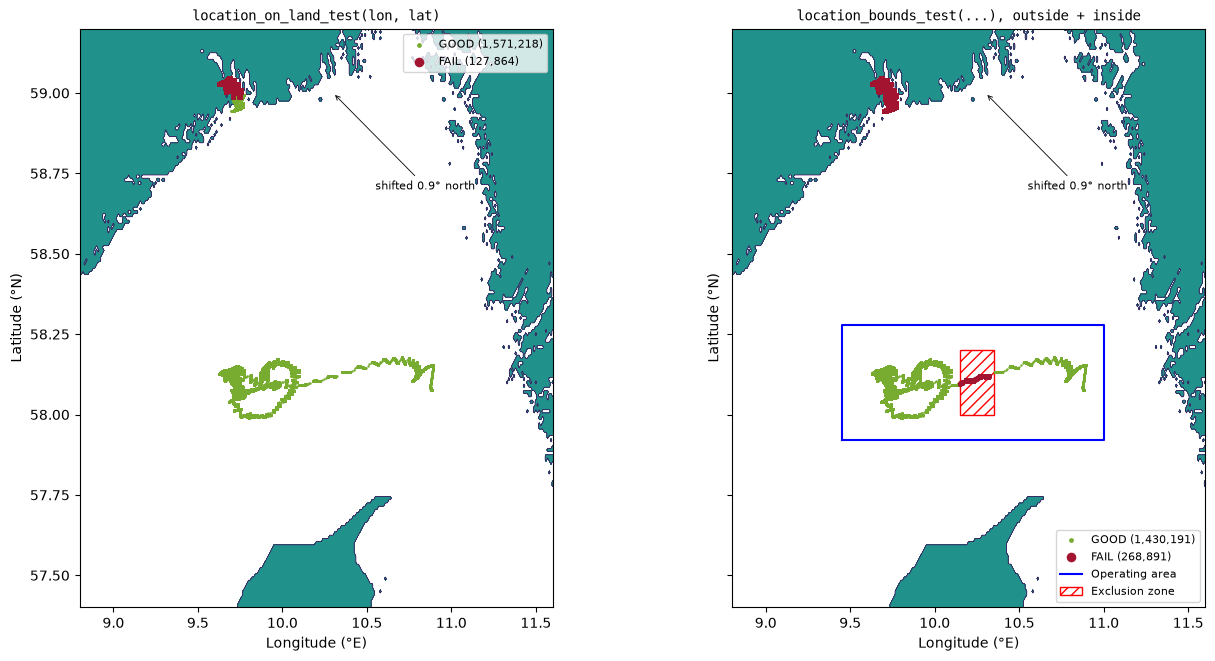

In [15]:
fig, axs = plotting_helpers.land_and_bounds_figure(
    ds.LONGITUDE, lat_shift, flags_land, flags_bounds, extent, operating_area, exclusion_zone,
)

Without the study area, we see the same results as before. Some of the poitns are on land. With the study area defined, *all* of the points near the coast fail, because they're outside the defined shape. Within the study area, however, there is also a subdomain which we're flagging inside of. So there is a second range of flags that has been applied.

This notebook is continued in part 3, which covers the Gross Range, Percentile Range and Climatology Tests.